In [1]:
from io import BytesIO
from pathlib import Path
from zipfile import ZipFile

import matplotlib.pyplot as plt
import pandas as pd
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

root = Path.cwd()
if root.name == "notebooks":
    root = root.parent

archive = root / "data" / "raw" / "OC-20250526T142605Z-1-001.zip"

with ZipFile(archive) as outer:
    with ZipFile(BytesIO(outer.read("OC/Agriculture Crop Yield.zip"))) as inner:
        agriculture_raw = pd.read_csv(inner.open("crop_yield.csv"))
    with ZipFile(BytesIO(outer.read("OC/Crop Yield Prediction Dataset.zip"))) as inner:
        history_raw = pd.read_csv(inner.open("yield_df.csv"))

target = "Yield_tons_per_hectare"
history_key = ["Area", "Item", "Year"]

for name, frame in {
    "Agriculture Crop Yield": agriculture_raw,
    "Crop Yield Prediction": history_raw,
}.items():
    print(name, frame.shape)
    display(pd.DataFrame({
        "type": frame.dtypes,
        "valeurs_manquantes": frame.isna().sum(),
    }))

print("Rendements négatifs :", agriculture_raw[target].lt(0).sum())
agriculture = (
    agriculture_raw.drop_duplicates()
    .dropna()
    .loc[lambda frame: frame[target].ge(0)]
    .reset_index(drop=True)
)

print("Observations agricoles conservées :", len(agriculture))
print("Clés historiques pays × culture × année :", 
      len(history_raw[history_key].drop_duplicates()))

Agriculture Crop Yield (1000000, 10)


,type,valeurs_manquantes
Region,str,0
Soil_Type,str,0
Crop,str,0
Rainfall_mm,float64,0
Temperature_Celsius,float64,0
Fertilizer_Used,bool,0
Irrigation_Used,bool,0
Weather_Condition,str,0
Days_to_Harvest,int64,0
Yield_tons_per_hectare,float64,0


Crop Yield Prediction (28242, 8)


,type,valeurs_manquantes
Unnamed: 0,int64,0
Area,str,0
Item,str,0
Year,int64,0
hg/ha_yield,int64,0
average_rain_fall_mm_per_year,float64,0
pesticides_tonnes,float64,0
avg_temp,float64,0


Rendements négatifs : 231
Observations agricoles conservées : 999769
Clés historiques pays × culture × année : 13130


,Variance expliquée (%)
CP1,25.08
CP2,25.02
CP3,24.97
CP4,24.93


,CP1,CP2,CP3,CP4
Rainfall_mm,-0.468,-0.312,0.814,0.144
Temperature_Celsius,0.466,-0.647,0.124,-0.591
Irrigation_Used,0.324,0.689,0.518,-0.390
Fertilizer_Used,0.678,-0.100,0.229,0.691


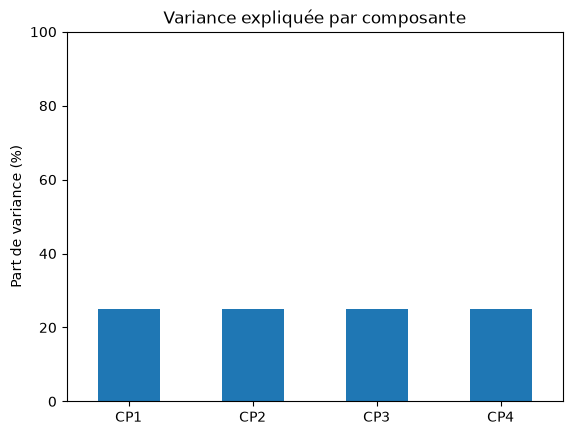

,Corrélation
Rainfall_mm,0.765
Fertilizer_Used,0.442
Irrigation_Used,0.353
Temperature_Celsius,0.085


In [2]:
features = [
    "Rainfall_mm", "Temperature_Celsius",
    "Irrigation_Used", "Fertilizer_Used",
]

X = agriculture[features].astype(float)
pca = PCA().fit(StandardScaler().fit_transform(X))
components = [f"CP{i}" for i in range(1, pca.n_components_ + 1)]

variance = pd.Series(
    pca.explained_variance_ratio_ * 100,
    index=components,
    name="Variance expliquée (%)",
)
display(variance.round(2).to_frame())
display(pd.DataFrame(
    pca.components_.T, index=features, columns=components
).round(3))

ax = variance.plot.bar(rot=0, ylim=(0, 100), title="Variance expliquée par composante")
ax.set_ylabel("Part de variance (%)")
plt.show()

correlations = (
    agriculture[features + [target]]
    .astype(float)
    .corr()[target]
    .drop(target)
)
display(correlations.sort_values(ascending=False).round(3).to_frame("Corrélation"))

In [3]:
crop_names = {
    "Maize": "Maize",
    "Rice, paddy": "Rice",
    "Soybeans": "Soybean",
    "Wheat": "Wheat",
}

annual = (
    history_raw.groupby(history_key, as_index=False)
    .agg(
        rainfall_mm=("average_rain_fall_mm_per_year", "median"),
        temperature_c=("avg_temp", "median"),
        pesticides_tonnes=("pesticides_tonnes", "median"),
    )
)

annual["Crop"] = annual["Item"].map(crop_names)

profiles = (
    annual.dropna(subset=["Crop"])
    .groupby("Crop", as_index=False)
    .agg(
        hist_country_year_count=("Year", "size"),
        hist_rainfall_mm_median=("rainfall_mm", "median"),
        hist_temperature_c_median=("temperature_c", "median"),
        hist_pesticides_tonnes_median=("pesticides_tonnes", "median"),
    )
)

consolidated = agriculture.merge(
    profiles, on="Crop", how="left", validate="many_to_one"
)
consolidated["has_historical_profile"] = (
    consolidated["hist_country_year_count"].notna()
)

assert len(consolidated) == len(agriculture)
display(profiles)
display(consolidated.groupby(
    ["Crop", "has_historical_profile"]
).size().rename("observations").to_frame())

output = root / "data" / "processed" / "crop_yield_consolidated.csv"
output.parent.mkdir(parents=True, exist_ok=True)
consolidated.to_csv(output, index=False)
print(f"CSV consolidé : {output}")

,Crop,hist_country_year_count,hist_rainfall_mm_median,hist_temperature_c_median,hist_pesticides_tonnes_median
0,Maize,2028,867.0,20.240,2166.500
1,Rice,1502,1131.5,21.570,2961.365
2,Soybean,1242,1020.0,18.475,4358.730
3,Wheat,1810,700.0,17.130,3101.340


,,observations
Crop,has_historical_profile,
Barley,False,166727
Cotton,False,166548
Maize,True,166785
Rice,True,166754
Soybean,True,166315
Wheat,True,166640


CSV consolidé : c:\Users\mouto\Documents\Jedha\OCR_Projects\OCR_Projet_12_analyse\data\processed\crop_yield_consolidated.csv


In [4]:
pip install mlflow

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [5]:
import sys

from sklearn.linear_model import LinearRegression
from sklearn.model_selection import KFold, cross_val_score, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer

sys.path.insert(0, str(root))
from src.models.train_regression import build_preprocessor

base_cols = [
    "Region", "Soil_Type", "Crop", "Rainfall_mm",
    "Temperature_Celsius", "Fertilizer_Used",
    "Irrigation_Used", "Weather_Condition",
]
hist_cols = [col for col in profiles.columns if col != "Crop"]
hist_cols += ["has_historical_profile"]

train_idx, _ = train_test_split(
    consolidated.index, test_size=0.20, random_state=42
)
train = consolidated.loc[train_idx].sample(n=100_000, random_state=42)
y_train = train[target]
crops = sorted(train["Crop"].unique())

def add_interactions(frame):
    interactions = {
        f"{crop}__{variable}": (
            frame["Crop"].eq(crop) * frame[variable].astype(float)
        )
        for crop in crops[1:]
        for variable in ["Rainfall_mm", "Irrigation_Used"]
    }
    return frame.assign(**interactions)

configs = {
    "Référence": (base_cols, None),
    "Avec historique": (base_cols + hist_cols, None),
    "Avec interactions": (base_cols, add_interactions),
}

cv = list(KFold(n_splits=5, shuffle=True, random_state=42).split(train))
models = {}
fold_scores = {}

for name, (columns, transform) in configs.items():
    X_train = train[columns]
    steps = []
    schema = X_train

    if transform is not None:
        steps.append(("interactions", FunctionTransformer(transform)))
        schema = transform(X_train.head(1))

    steps.extend([
        ("preprocess", build_preprocessor(schema)),
        ("model", LinearRegression()),
    ])
    model = Pipeline(steps)
    fold_scores[name] = -cross_val_score(
        model, X_train, y_train, cv=cv,
        scoring="neg_mean_absolute_error", error_score="raise",
    )
    models[name] = model.fit(X_train, y_train)

scores = pd.DataFrame(fold_scores)
display(pd.DataFrame({
    "MAE moyenne (t/ha)": scores.mean(),
    "Écart-type (t/ha)": scores.std(ddof=0),
    "Δ MAE vs référence (t/ha)": scores.sub(scores["Référence"], axis=0).mean(),
}).round(6))

c:\Users\mouto\Documents\Jedha\OCR_Projects\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


,MAE moyenne (t/ha),Écart-type (t/ha),Δ MAE vs référence (t/ha)
Référence,0.398626,0.001483,0.000000
Avec historique,0.398626,0.001483,-0.000000
Avec interactions,0.398651,0.001460,0.000025


In [6]:
contexts = (
    train[base_cols].drop(columns="Crop")
    .sample(n=2_000, random_state=42)
    .reset_index(drop=True)
)

scenarios = (
    contexts.rename_axis("scenario").reset_index()
    .merge(pd.DataFrame({"Crop": crops}), how="cross")
    .merge(profiles, on="Crop", how="left", validate="many_to_one")
)
scenarios["has_historical_profile"] = scenarios["hist_country_year_count"].notna()

ranking_summary = []

for name, model in models.items():
    columns = configs[name][0]
    simulations = scenarios.assign(
        prediction=model.predict(scenarios[columns])
    )
    ranking = simulations.sort_values(
        ["scenario", "prediction", "Crop"],
        ascending=[True, False, True],
    )

    winners = ranking.groupby("scenario").head(1)["Crop"].value_counts()
    top_two = ranking.groupby("scenario").head(2)
    gaps_kg_ha = -1_000 * top_two.groupby("scenario")["prediction"].diff().dropna()

    ranking_summary.append({
        "Configuration": name,
        "Cultures arrivées premières": winners.to_dict(),
        "Écart médian (kg/ha)": gaps_kg_ha.median(),
        "95e percentile de l’écart (kg/ha)": gaps_kg_ha.quantile(0.95),
    })

display(pd.DataFrame(ranking_summary).round(2))

,Configuration,Cultures arrivées premières,Écart médian (kg/ha),95e percentile de l’écart (kg/ha)
0,Référence,{'Soybean': 2000},0.70,0.70
1,Avec historique,{'Soybean': 2000},0.70,0.70
2,Avec interactions,"{'Soybean': 992, 'Rice': 983, 'Cotton': 25}",2.34,6.63
